# 🎯 CNN Task: Build Your Own CNN for CIFAR-10

## Challenge Overview
In this hands-on task, you'll build your own CNN architecture to classify images from the CIFAR-10 dataset. This is your chance to apply everything you've learned about ConvBlocks!

## Your Mission
- **Dataset**: CIFAR-10 (10 classes, 32×32 RGB images)
- **Goal**: Build a CNN that achieves good accuracy
- **Focus**: Architecture design using ConvBlocks
- **Constraint**: Keep it efficient (< 1M parameters)

## CIFAR-10 Classes
0. ✈️ Airplane
1. 🚗 Automobile  
2. 🐦 Bird
3. 🐱 Cat
4. 🦌 Deer
5. 🐕 Dog
6. 🐸 Frog
7. 🐴 Horse
8. 🚢 Ship
9. 🚚 Truck

## What You'll Do
1. **Explore** the CIFAR-10 dataset
2. **Design** your CNN architecture
3. **Train** your model
4. **Evaluate** performance
5. **Experiment** with different architectures

## Step 1: Setup and Data Loading (Boilerplate)

**Note**: This section provides the boilerplate code for data loading. You don't need to modify this part - just run it to get the data ready.

In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
import torchvision
import torchvision.transforms as transforms
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
import numpy as np
from tqdm.auto import tqdm
import time

# Set device
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

# Set random seed for reproducibility
torch.manual_seed(42)
np.random.seed(42)

Using device: cuda


In [2]:
# Data preprocessing - Simple transforms (no augmentation yet)
transform_train = transforms.Compose([
    transforms.ToTensor(),  # Convert PIL Image to tensor and scale to [0, 1]
    transforms.Normalize((0.4914, 0.4822, 0.4465), (0.2023, 0.1994, 0.2010))  # CIFAR-10 mean and std
])

transform_test = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.4914, 0.4822, 0.4465), (0.2023, 0.1994, 0.2010))
])

# Load CIFAR-10 dataset
print("Downloading CIFAR-10 dataset...")
train_dataset = torchvision.datasets.CIFAR10(
    root='./data', train=True, download=True, transform=transform_train
)

test_dataset = torchvision.datasets.CIFAR10(
    root='./data', train=False, download=True, transform=transform_test
)

# Create data loaders
batch_size = 128
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=2)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False, num_workers=2)

# CIFAR-10 class names
classes = ['plane', 'car', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']

print(f"✅ Data loaded successfully!")
print(f"Training samples: {len(train_dataset)}")
print(f"Test samples: {len(test_dataset)}")
print(f"Batch size: {batch_size}")
print(f"Number of classes: {len(classes)}")

100%|██████████| 170M/170M [00:04<00:00, 42.0MB/s]


✅ Data loaded successfully!
Training samples: 50000
Test samples: 10000
Batch size: 128
Number of classes: 10


## Step 2: Explore the Dataset

Let's look at some sample images to understand what we're working with:

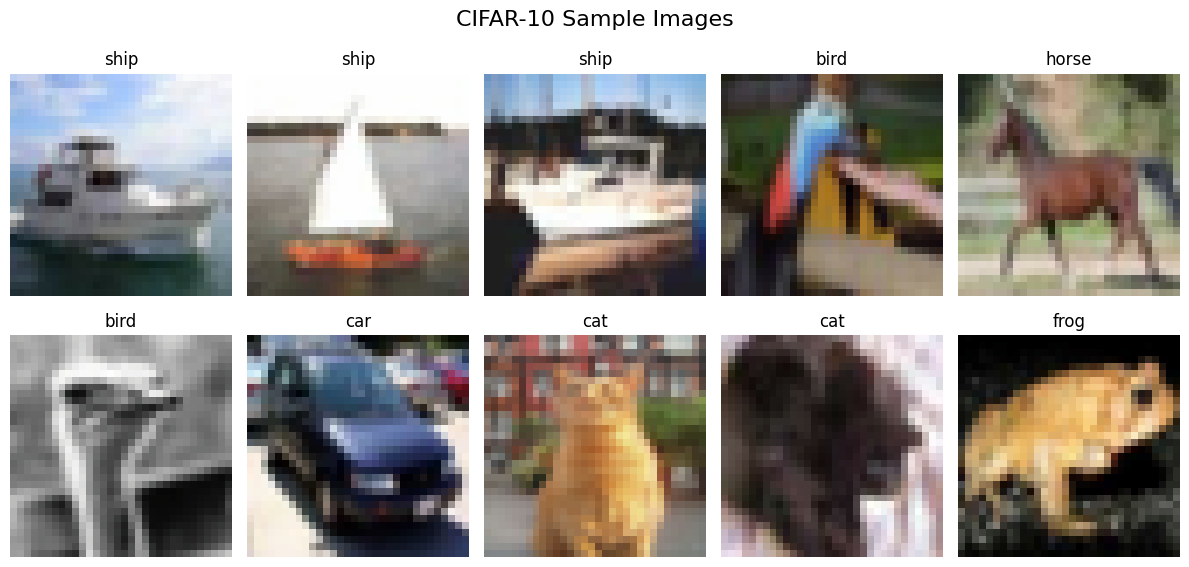


Dataset Statistics:
Image size: 32 × 32 × 3 (RGB)
Total pixels per image: 3072 = 3,072
If we used a fully connected layer: 3,072 × 1,000 = 3,072,000 parameters!
This is why we need CNNs! 🚀


In [3]:
def show_sample_images(dataset, classes, num_samples=10):
    """
    Display sample images from the dataset
    """
    fig, axes = plt.subplots(2, 5, figsize=(12, 6))
    fig.suptitle('CIFAR-10 Sample Images', fontsize=16)

    for i in range(num_samples):
        # Get a random sample
        idx = np.random.randint(len(dataset))
        image, label = dataset[idx]

        # Convert tensor to numpy and denormalize for display
        image = image.numpy().transpose(1, 2, 0)
        # Denormalize
        mean = np.array([0.4914, 0.4822, 0.4465])
        std = np.array([0.2023, 0.1994, 0.2010])
        image = image * std + mean
        image = np.clip(image, 0, 1)  # Ensure values are in [0, 1]

        # Plot
        row, col = i // 5, i % 5
        axes[row, col].imshow(image)
        axes[row, col].set_title(f'{classes[label]}')
        axes[row, col].axis('off')

    plt.tight_layout()
    plt.show()

# Show sample images
show_sample_images(train_dataset, classes)

# Dataset statistics
print("\nDataset Statistics:")
print(f"Image size: 32 × 32 × 3 (RGB)")
print(f"Total pixels per image: {32 * 32 * 3} = 3,072")
print(f"If we used a fully connected layer: 3,072 × 1,000 = 3,072,000 parameters!")
print(f"This is why we need CNNs! 🚀")

## Step 3: Your Task - Design Your CNN Architecture

**🎯 YOUR CHALLENGE**: Design a CNN architecture using the ConvBlocks you learned about!

### Requirements:
1. **Input**: 32×32×3 RGB images
2. **Output**: 10 classes (CIFAR-10)
3. **Use**: ConvBlocks we learned (Standard, Depthwise Separable, etc.)

### Architecture Ideas:
- Start with ConvBlocks to extract features
- Use pooling to downsample
- End with classification layers
- Consider using different block types!

### Template Architecture:
```
Input (32×32×3)
    ↓
ConvBlock 1 → (16×16×channels)
    ↓  
ConvBlock 2 → (8×8×channels)
    ↓
ConvBlock 3 → (4×4×channels)
    ↓
Linear Layer → 10 classes
```

## 🎯 YOUR TURN: Design Your CNN

**Complete the `MyCNN` class below**. You can:

1. **Use Standard ConvBlocks** for a simple, proven approach
2. **Use Depthwise Separable Blocks** for efficiency  
3. **Mix different block types** for a hybrid approach
4. **Experiment** with different channel sizes

### Tips:
- Start simple, then iterate
- CIFAR-10 images are small (32×32), so don't go too deep
- Use `nn.AdaptiveAvgPool2d((1, 1))` for global pooling
- Remember: Input is 3 channels, output should be 10 classes

In [4]:
class StandardConvBlock(nn.Module):
    """
    Standard ConvBlock: Conv2d → BatchNorm2d → ReLU → [Optional: Pooling]
    """
    def __init__(self, in_channels, out_channels, kernel_size=3, stride=1, padding=1,
                 use_pooling=True, pool_size=2):
        super().__init__()

        # Core layers
        self.conv = nn.Conv2d(in_channels, out_channels, kernel_size, stride, padding)
        self.bn = nn.BatchNorm2d(out_channels)
        self.relu = nn.ReLU(inplace=True)

        # Optional pooling
        self.use_pooling = use_pooling
        if use_pooling:
            self.pool = nn.MaxPool2d(pool_size)

    def forward(self, x):
        # Standard pattern: Conv → BN → ReLU → Pool
        x = self.conv(x)
        x = self.bn(x)
        x = self.relu(x)

        if self.use_pooling:
            x = self.pool(x)

        return x

class MyCNN(nn.Module):
    """
    🎯 YOUR CNN ARCHITECTURE
    Design your own CNN for CIFAR-10 classification!
    """
    def __init__(self, num_classes=10):
        super().__init__()

        # Feature extraction with ConvBlocks
        self.block1 = StandardConvBlock(3, 32)      # 32x32 → 16x16
        self.block2 = StandardConvBlock(32, 64)     # 16x16 → 8x8
        self.block3 = StandardConvBlock(64, 128)    # 8x8 → 4x4
        self.block4 = StandardConvBlock(128, 256, use_pooling=False)  # 4x4 → 4x4
        self.global_pool = nn.AdaptiveAvgPool2d((1, 1))  # Any size → 1x1

        self.classifier = nn.Linear(256, num_classes)

    def forward(self, x):
        # Feature extraction
        x = self.block1(x)
        x = self.block2(x)
        x = self.block3(x)
        x = self.block4(x)

        x = self.global_pool(x)  # [B, 256, 4, 4] → [B, 256, 1, 1]
        x = x.view(x.size(0), -1)  # [B, 256, 1, 1] → [B, 256]
        x = self.classifier(x)     # [B, 256] → [B, num_classes]

        return x

# Create your model
model = MyCNN(num_classes=10).to(device)

# Let's analyze your architecture
def analyze_model(model):
    """
    Analyze the model architecture and parameters
    """
    total_params = sum(p.numel() for p in model.parameters())
    trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

    print("🔍 Model Analysis:")
    print("=" * 30)
    print(f"Total parameters: {total_params:,}")
    print(f"Trainable parameters: {trainable_params:,}")

    # Model size
    model_size_mb = total_params * 4 / (1024 * 1024)  # 4 bytes per float32
    print(f"Estimated model size: {model_size_mb:.2f} MB")

    # Test forward pass
    model.eval()
    with torch.no_grad():
        test_input = torch.randn(1, 3, 32, 32).to(device)
        output = model(test_input)
        print(f"Input shape: {test_input.shape}")
        print(f"Output shape: {output.shape}")

        if output.shape[1] == 10:
            print("✅ Correct output shape for CIFAR-10!")
        else:
            print(f"❌ Wrong output shape! Expected (batch_size, 10), got {output.shape}")

analyze_model(model)

🔍 Model Analysis:
Total parameters: 391,946
Trainable parameters: 391,946
Estimated model size: 1.50 MB
Input shape: torch.Size([1, 3, 32, 32])
Output shape: torch.Size([1, 10])
✅ Correct output shape for CIFAR-10!


## Step 4: Training Setup (Boilerplate)

Here's the training code - you don't need to modify this part:

In [5]:
# Training setup
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)
scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=10, gamma=0.1)

def train_model(model, train_loader, criterion, optimizer, device):
    """
    Train the model for one epoch
    """
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    pbar = tqdm(train_loader, desc='Training')
    for batch_idx, (data, targets) in enumerate(pbar):
        data, targets = data.to(device), targets.to(device)

        # Forward pass
        optimizer.zero_grad()
        outputs = model(data)
        loss = criterion(outputs, targets)

        # Backward pass
        loss.backward()
        optimizer.step()

        # Statistics
        running_loss += loss.item()
        _, predicted = outputs.max(1)
        total += targets.size(0)
        correct += predicted.eq(targets).sum().item()

        # Update progress bar
        pbar.set_postfix({
            'Loss': f'{running_loss/(batch_idx+1):.3f}',
            'Acc': f'{100.*correct/total:.1f}%'
        })

    epoch_loss = running_loss / len(train_loader)
    epoch_acc = 100. * correct / total
    return epoch_loss, epoch_acc

def test_model(model, test_loader, criterion, device):
    """
    Test the model
    """
    model.eval()
    test_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        pbar = tqdm(test_loader, desc='Testing')
        for data, targets in pbar:
            data, targets = data.to(device), targets.to(device)
            outputs = model(data)
            test_loss += criterion(outputs, targets).item()

            _, predicted = outputs.max(1)
            total += targets.size(0)
            correct += predicted.eq(targets).sum().item()

            pbar.set_postfix({'Acc': f'{100.*correct/total:.1f}%'})

    test_loss /= len(test_loader)
    test_acc = 100. * correct / total
    return test_loss, test_acc

print("✅ Training functions ready!")

✅ Training functions ready!


## Step 5: Train Your Model!

Now let's train your CNN and see how it performs:

In [6]:
# Training parameters
num_epochs = 5  # Start with a few epochs for quick testing

print(f"🚀 Starting training for {num_epochs} epochs...")
print(f"Model: {model.__class__.__name__}")
print(f"Device: {device}")
print("=" * 50)

# Track training history
train_losses = []
train_accs = []
test_losses = []
test_accs = []

start_time = time.time()

for epoch in range(num_epochs):
    print(f"\nEpoch {epoch+1}/{num_epochs}")
    print("-" * 30)

    # Train
    train_loss, train_acc = train_model(model, train_loader, criterion, optimizer, device)

    # Test
    test_loss, test_acc = test_model(model, test_loader, criterion, device)

    # Update scheduler
    scheduler.step()

    # Store results
    train_losses.append(train_loss)
    train_accs.append(train_acc)
    test_losses.append(test_loss)
    test_accs.append(test_acc)

    # Print epoch results
    print(f"Train Loss: {train_loss:.3f}, Train Acc: {train_acc:.1f}%")
    print(f"Test Loss:  {test_loss:.3f}, Test Acc:  {test_acc:.1f}%")

end_time = time.time()
training_time = end_time - start_time

print("\n" + "=" * 50)
print("🎉 Training Complete!")
print(f"⏱️  Total training time: {training_time:.2f} seconds")
print(f"🎯 Final test accuracy: {test_accs[-1]:.1f}%")

🚀 Starting training for 5 epochs...
Model: MyCNN
Device: cuda

Epoch 1/5
------------------------------


Training:   0%|          | 0/391 [00:00<?, ?it/s]

Testing:   0%|          | 0/79 [00:00<?, ?it/s]

Train Loss: 1.194, Train Acc: 57.2%
Test Loss:  1.043, Test Acc:  62.4%

Epoch 2/5
------------------------------


Training:   0%|          | 0/391 [00:00<?, ?it/s]

...

Testing:   0%|          | 0/79 [00:00<?, ?it/s]

Train Loss: 0.603, Train Acc: 78.8%
Test Loss:  0.757, Test Acc:  73.6%

Epoch 5/5
------------------------------


Training:   0%|          | 0/391 [00:00<?, ?it/s]

Testing:   0%|          | 0/79 [00:00<?, ?it/s]

Train Loss: 0.527, Train Acc: 81.7%
Test Loss:  0.704, Test Acc:  75.7%

🎉 Training Complete!
⏱️  Total training time: 88.83 seconds
🎯 Final test accuracy: 75.7%


## Step 6: Analyze Results

Let's visualize your training progress and analyze the results:

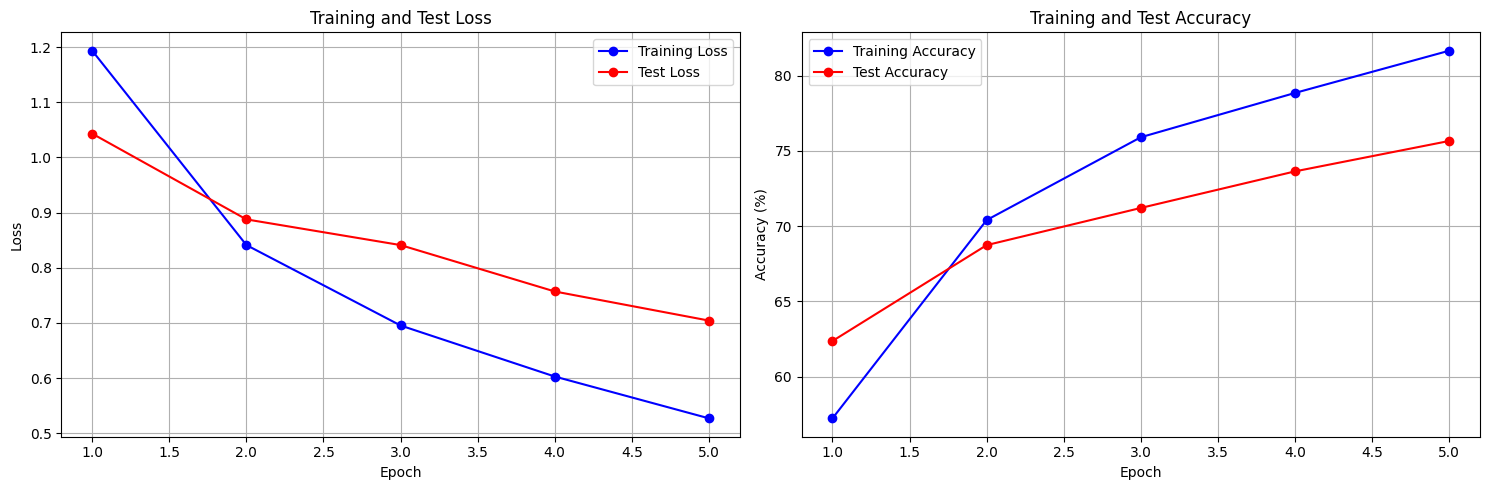

📊 Performance Summary:
Best training accuracy: 81.7%
Best test accuracy: 75.7%
Final test accuracy: 75.7%
✅ Good balance between training and test (gap: 6.0%)


In [7]:
# Plot training curves
def plot_training_curves(train_losses, train_accs, test_losses, test_accs):
    """
    Plot training and validation curves
    """
    epochs = range(1, len(train_losses) + 1)

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

    # Loss plot
    ax1.plot(epochs, train_losses, 'bo-', label='Training Loss')
    ax1.plot(epochs, test_losses, 'ro-', label='Test Loss')
    ax1.set_title('Training and Test Loss')
    ax1.set_xlabel('Epoch')
    ax1.set_ylabel('Loss')
    ax1.legend()
    ax1.grid(True)

    # Accuracy plot
    ax2.plot(epochs, train_accs, 'bo-', label='Training Accuracy')
    ax2.plot(epochs, test_accs, 'ro-', label='Test Accuracy')
    ax2.set_title('Training and Test Accuracy')
    ax2.set_xlabel('Epoch')
    ax2.set_ylabel('Accuracy (%)')
    ax2.legend()
    ax2.grid(True)

    plt.tight_layout()
    plt.show()

plot_training_curves(train_losses, train_accs, test_losses, test_accs)

# Performance summary
print("📊 Performance Summary:")
print("=" * 30)
print(f"Best training accuracy: {max(train_accs):.1f}%")
print(f"Best test accuracy: {max(test_accs):.1f}%")
print(f"Final test accuracy: {test_accs[-1]:.1f}%")

# Overfitting check
gap = train_accs[-1] - test_accs[-1]
if gap > 10:
    print(f"⚠️  Possible overfitting (gap: {gap:.1f}%)")
    print("💡 Try: regularization, dropout, or more data")
elif gap < -5:
    print(f"🤔 Test accuracy higher than training (gap: {gap:.1f}%)")
    print("💡 This can happen with small datasets or strong regularization")
else:
    print(f"✅ Good balance between training and test (gap: {gap:.1f}%)")

## Step 7: Test Individual Predictions

Let's see how your model performs on individual images:

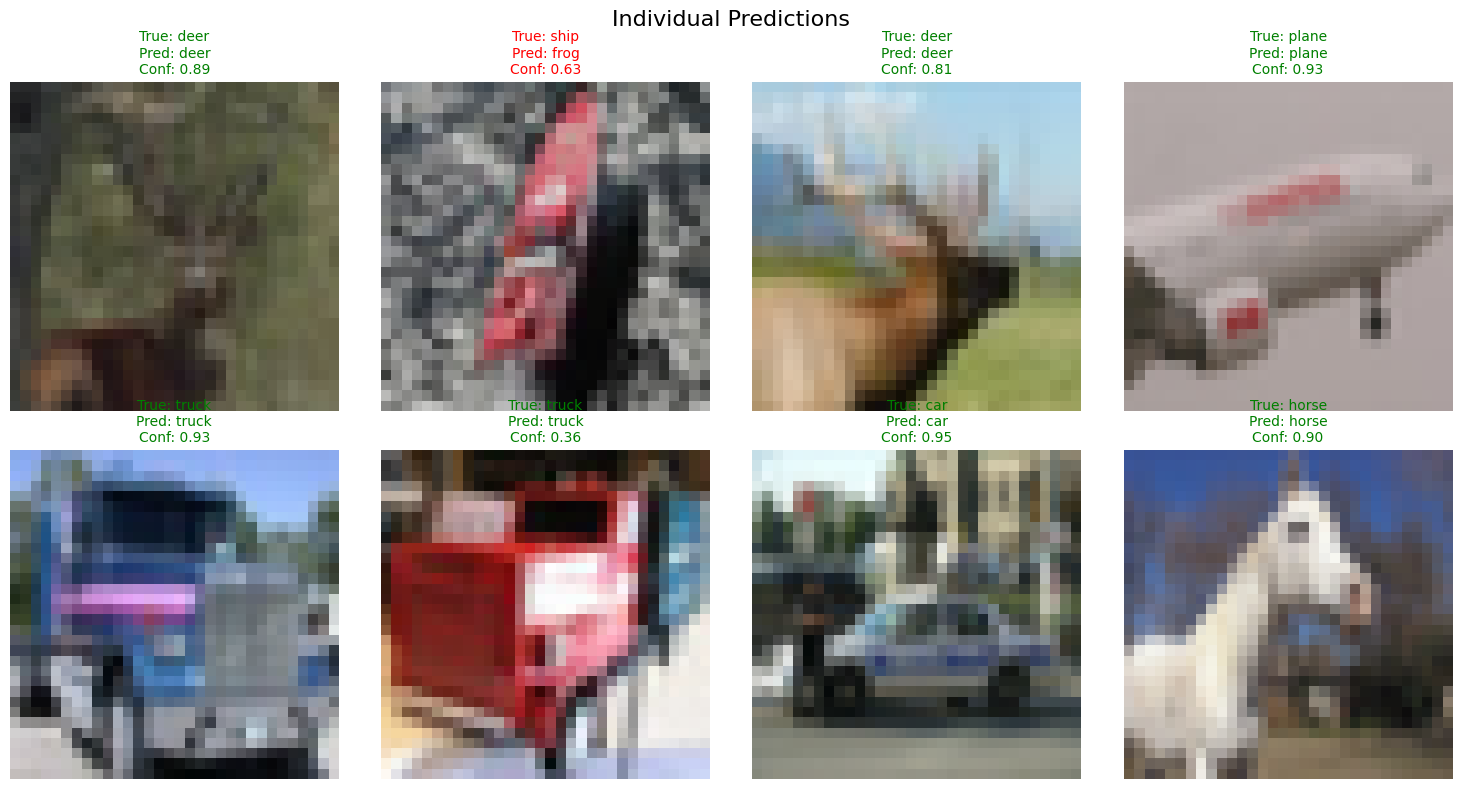


✅ Correct predictions: 7/8 (87.5%)


In [8]:
def test_individual_predictions(model, test_dataset, classes, num_samples=8):
    """
    Test model on individual images and show predictions
    """
    model.eval()

    fig, axes = plt.subplots(2, 4, figsize=(15, 8))
    fig.suptitle('Individual Predictions', fontsize=16)

    correct_predictions = 0

    for i in range(num_samples):
        # Get random sample
        idx = np.random.randint(len(test_dataset))
        image, true_label = test_dataset[idx]

        # Make prediction
        with torch.no_grad():
            image_batch = image.unsqueeze(0).to(device)  # Add batch dimension
            output = model(image_batch)
            probabilities = F.softmax(output, dim=1)
            confidence, predicted = torch.max(probabilities, 1)

        predicted_label = predicted.item()
        confidence_score = confidence.item()

        # Count correct predictions
        if predicted_label == true_label:
            correct_predictions += 1

        # Prepare image for display
        display_image = image.numpy().transpose(1, 2, 0)
        mean = np.array([0.4914, 0.4822, 0.4465])
        std = np.array([0.2023, 0.1994, 0.2010])
        display_image = display_image * std + mean
        display_image = np.clip(display_image, 0, 1)

        # Plot
        row, col = i // 4, i % 4
        axes[row, col].imshow(display_image)

        # Color-code the title based on correctness
        color = 'green' if predicted_label == true_label else 'red'
        title = f'True: {classes[true_label]}\nPred: {classes[predicted_label]}\nConf: {confidence_score:.2f}'
        axes[row, col].set_title(title, color=color, fontsize=10)
        axes[row, col].axis('off')

    plt.tight_layout()
    plt.show()

    print(f"\n✅ Correct predictions: {correct_predictions}/{num_samples} ({100*correct_predictions/num_samples:.1f}%)")

# Test individual predictions
test_individual_predictions(model, test_dataset, classes)

## Step 8: Experiment and Improve! 🔬

Now it's time to experiment and improve your model. Try these ideas:

### 🎯 Experiments to Try:

1. **Different Architectures**:
   - Try DepthwiseSeparableBlocks instead of StandardConvBlocks
   - Mix different block types
   - Add more or fewer layers

2. **Different Channel Sizes**:
   - Try [16, 32, 64] instead of [32, 64, 128]
   - Try [64, 128, 256] for more capacity

3. **Add Regularization**:
   - Add `nn.Dropout(0.5)` before the classifier
   - Try different dropout rates

4. **Training Longer**:
   - Increase `num_epochs` to 10 or 20
   - Try different learning rates

### 📊 Target Benchmarks:
- **Beginner**: > 60% test accuracy
- **Intermediate**: > 70% test accuracy  
- **Advanced**: > 80% test accuracy
- **Expert**: > 85% test accuracy

**Remember**: The goal is to learn, not just get the highest score! Try to understand:
- Why certain architectures work better
- How parameter count affects performance
- What causes overfitting vs underfitting

In [ ]:
# 🎯 Experiment Area - Modify this cell to try different architectures!

class ExperimentalCNN(nn.Module):
    """
    🔬 Your experimental architecture
    Try different ideas here!
    """
    def __init__(self, num_classes=10):
        super().__init__()

        # 🎯 EXPERIMENT: Try different architectures here!
        # Ideas:
        # - Use DepthwiseSeparableBlock for efficiency
        # - Try different channel progressions
        # - Mix different block types
        pass



    def forward(self, x):
        # Wrap up the forward pass here

        return x

# 🎯 Uncomment these lines to test your experimental model:
# experimental_model = ExperimentalCNN().to(device)
# analyze_model(experimental_model)
#
# # Train experimental model
# exp_optimizer = optim.Adam(experimental_model.parameters(), lr=0.001)
# # ... (use the same training code as above)

print("🔬 Experimental architecture ready!")
print("💡 Uncomment the lines above to test it!")

## 🎉 Congratulations!

You've successfully:

✅ **Built** your own CNN architecture  
✅ **Trained** it on CIFAR-10 dataset  
✅ **Evaluated** its performance  
✅ **Analyzed** the results  
✅ **Experimented** with improvements  

## 🧠 Key Learnings:

1. **ConvBlocks** make building CNNs much easier and more modular
2. **Parameter efficiency** matters - more parameters ≠ better performance
3. **Different block types** have different trade-offs (standard vs depthwise separable)
4. **Training dynamics** show overfitting, underfitting, or good balance
5. **Real datasets** like CIFAR-10 are challenging but achievable with good architecture

## 🚀 Next Steps:

- **Try more architectures**: Mix and match different ConvBlocks
- **Longer training**: Train for more epochs with learning rate scheduling
- **Data augmentation**: Coming in future lessons!
- **Famous architectures**: Learn about ResNet, MobileNet, EfficientNet
- **Transfer learning**: Use pre-trained models

## 💭 Reflection Questions:

1. What was your best test accuracy? How does it compare to the benchmarks?
2. Which architecture worked best - standard blocks, depthwise separable, or hybrid?
3. Did you observe overfitting? How could you reduce it?
4. How did parameter count relate to performance in your experiments?
5. What would you try next to improve performance?

**Great job on completing your first CNN project!** 🎯